#***ECO LIFESTYLE PREDICTOR***

---



In [1]:
import io
from google.colab import files
uploaded = files.upload()

Saving lifestyle_sustainability_data.csv to lifestyle_sustainability_data.csv


##**Dataset Loading and Initial Inspection**

In [2]:
# Load and inspect the dataset

import pandas as pd

df = pd.read_csv("lifestyle_sustainability_data.csv")

print("Shape of the dataset:")
print("Rows:", df.shape[0], "\nColumns:", df.shape[1])
print("\n")

print("First 5 rows of the dataset:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types of each column:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

Shape of the dataset:
Rows: 499 
Columns: 20


First 5 rows of the dataset:


,ParticipantID,Age,Location,DietType,LocalFoodFrequency,TransportationMode,EnergySource,HomeType,HomeSize,ClothingFrequency,SustainableBrands,EnvironmentalAwareness,CommunityInvolvement,MonthlyElectricityConsumption,MonthlyWaterConsumption,Gender,UsingPlasticProducts,DisposalMethods,PhysicalActivities,Rating
0,1,35,Urban,Mostly Plant-Based,Often,Bike,Renewable,Apartment,800,Rarely,True,5,High,100,1500,Female,Rarely,Composting,High,5
1,2,28,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1500,Sometimes,True,4,Moderate,250,3000,Male,Sometimes,Recycling,Moderate,4
2,3,65,Rural,Mostly Animal-Based,Rarely,Car,Non-Renewable,House,2500,Often,False,2,Low,400,4500,Male,Often,Landfill,Low,1
3,4,42,Urban,Mostly Plant-Based,Often,Walk,Renewable,Apartment,950,Sometimes,True,4,Moderate,150,2000,Female,Rarely,Recycling,High,5
4,5,31,Suburban,Balanced,Sometimes,Public Transit,Mixed,House,1800,Often,True,3,Low,300,3500,Non-Binary,Sometimes,Combination,Moderate,3



Column names:
['ParticipantID', 'Age', 'Location', 'DietType', 'LocalFoodFrequency', 'TransportationMode', 'EnergySource', 'HomeType', 'HomeSize', 'ClothingFrequency', 'SustainableBrands', 'EnvironmentalAwareness', 'CommunityInvolvement', 'MonthlyElectricityConsumption', 'MonthlyWaterConsumption', 'Gender', 'UsingPlasticProducts', 'DisposalMethods', 'PhysicalActivities', 'Rating']

Data types of each column:
ParticipantID                     int64
Age                               int64
Location                         object
DietType                         object
LocalFoodFrequency               object
TransportationMode               object
EnergySource                     object
HomeType                         object
HomeSize                          int64
ClothingFrequency                object
SustainableBrands                  bool
EnvironmentalAwareness            int64
CommunityInvolvement             object
MonthlyElectricityConsumption     int64
MonthlyWaterConsumption    

In [3]:
# Handle missing values
df['CommunityInvolvement'] = df['CommunityInvolvement'].fillna("Unknown")
df['PhysicalActivities'] = df['PhysicalActivities'].fillna("Unknown")

# Verifying
print("\nMissing values per column after handling:")
display(df.isnull().sum())


Missing values per column after handling:


,0
ParticipantID,0
Age,0
Location,0
DietType,0
LocalFoodFrequency,0
TransportationMode,0
EnergySource,0
HomeType,0
HomeSize,0
ClothingFrequency,0


## **Exploratory Data Analysis (EDA)**

In [4]:
# Statistical summary
print(df.describe())

# Average age of participants
average_age = round(df["Age"].mean(), 2)
print(f"\nThe average age of participants is: {average_age}")

# Average monthly electricity consumption
avg_electricity = round(df["MonthlyElectricityConsumption"].mean(), 2)
print(f"The average monthly electricity consumption is: {avg_electricity} kWh")

# Average monthly water consumption
avg_water = round(df["MonthlyWaterConsumption"].mean(), 2)
print(f"The average monthly water consumption is: {avg_water} liters")

# Average home size
avg_home_size = round(df["HomeSize"].mean(), 2)
print(f"The average home size is: {avg_home_size} sq ft")

       ParticipantID         Age     HomeSize  EnvironmentalAwareness  \
count     499.000000  499.000000   499.000000              499.000000   
mean      250.024048   44.052104  1518.046092                3.062124   
std       144.233925   14.904828   672.212235                1.342145   
min         1.000000   18.000000   407.000000                1.000000   
25%       125.500000   31.000000   951.500000                2.000000   
50%       250.000000   44.000000  1450.000000                3.000000   
75%       374.500000   58.000000  1995.000000                4.000000   
max       500.000000   96.000000  2997.000000                5.000000   

       MonthlyElectricityConsumption  MonthlyWaterConsumption      Rating  
count                     499.000000               499.000000  499.000000  
mean                      291.963928              3139.521042    3.430862  
std                       120.482275              1224.609306    1.502585  
min                        55.000000  

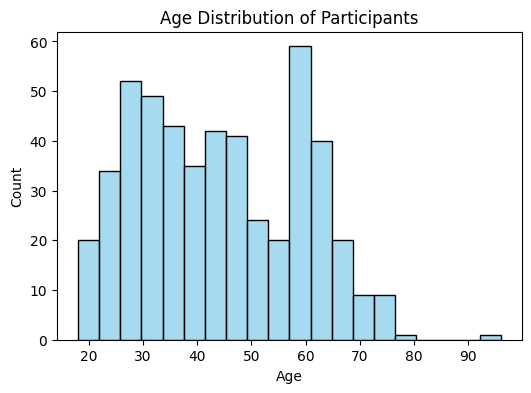

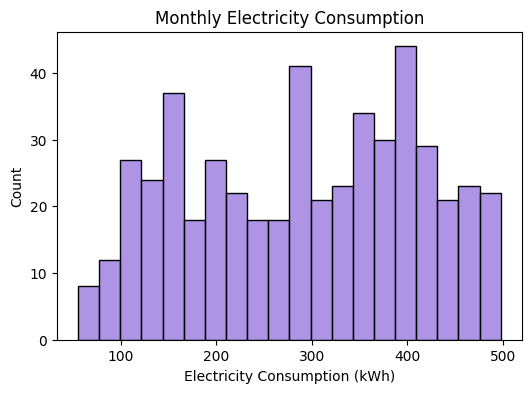

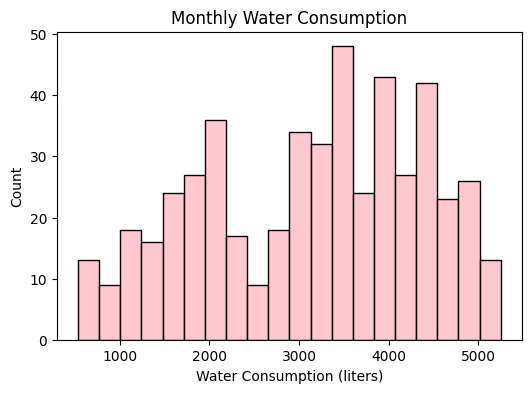

/tmp/ipykernel_3981/296388497.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='TransportationMode', data=df, palette="pastel")


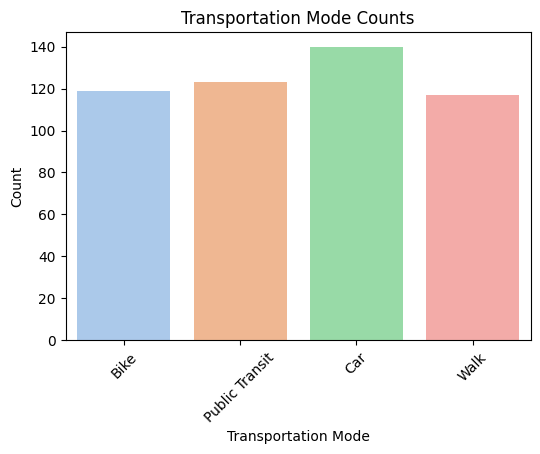

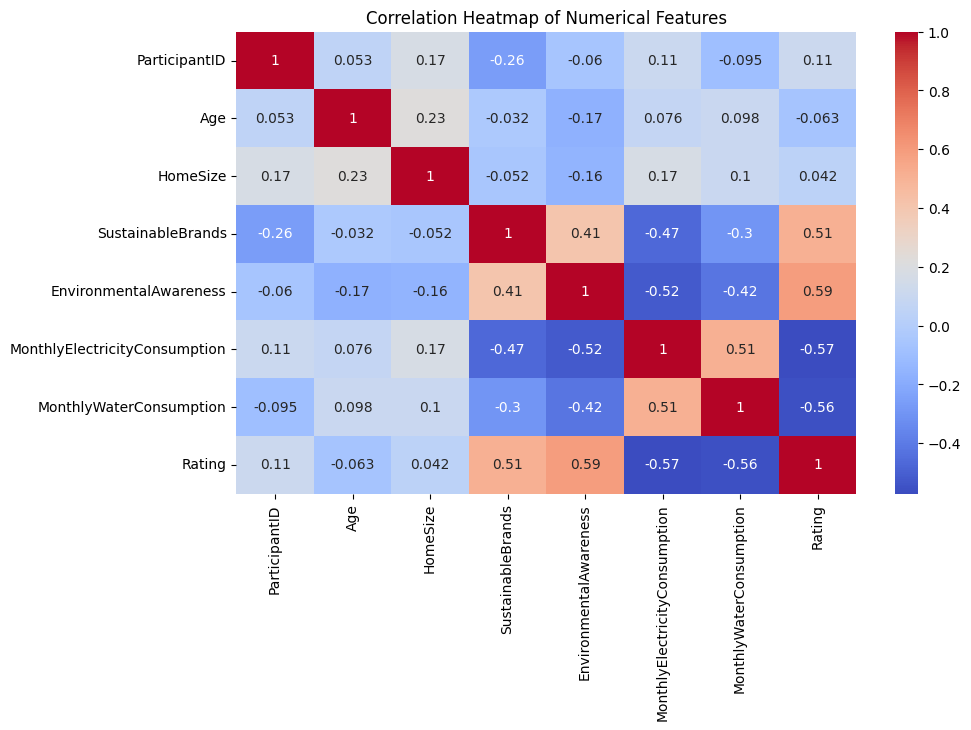

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Age distribution
plt.figure(figsize=(6,4))
sns.histplot(df['Age'], bins=20, color="skyblue")
plt.title("Age Distribution of Participants")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

# Electricity consumption distribution
plt.figure(figsize=(6,4))
sns.histplot(df['MonthlyElectricityConsumption'], bins=20, color="mediumpurple")
plt.title("Monthly Electricity Consumption")
plt.xlabel("Electricity Consumption (kWh)")
plt.ylabel("Count")
plt.show()

# Water consumption distribution
plt.figure(figsize=(6,4))
sns.histplot(df['MonthlyWaterConsumption'], bins=20, color="lightpink")
plt.title("Monthly Water Consumption")
plt.xlabel("Water Consumption (liters)")
plt.ylabel("Count")
plt.show()

# Transportation mode counts
plt.figure(figsize=(6,4))
sns.countplot(x='TransportationMode', data=df, palette="pastel")
plt.title("Transportation Mode Counts")
plt.xlabel("Transportation Mode")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

# Correlation heatmap (numerical features only)
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", cbar="true")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

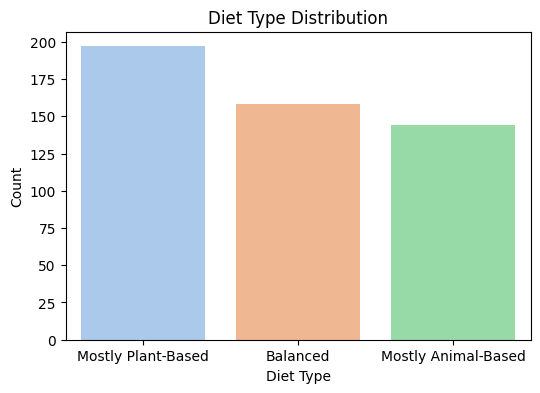

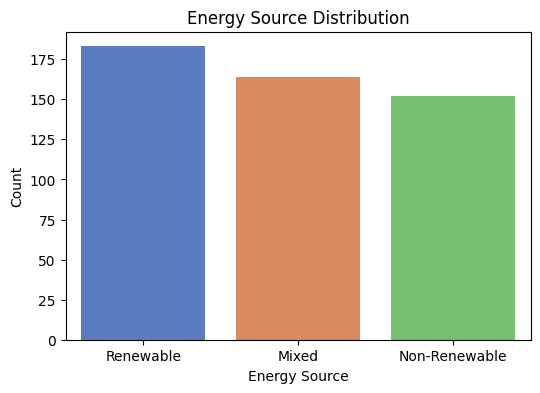

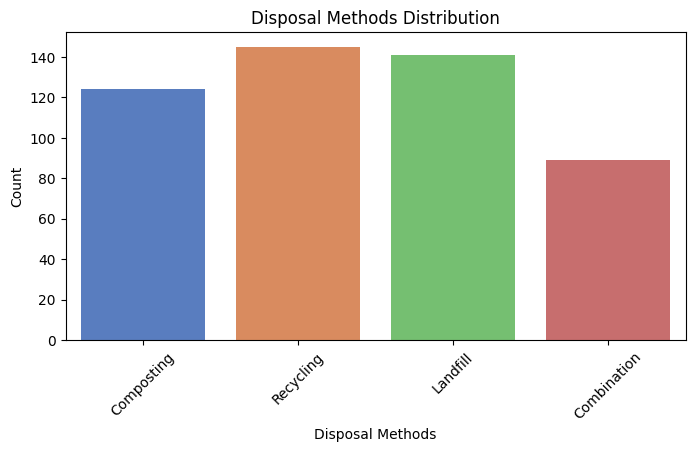

In [6]:
# Additional plots

import matplotlib.pyplot as plt
import seaborn as sns

# Diet Type Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='DietType', hue='DietType', data=df, palette="pastel", legend=False)
plt.title("Diet Type Distribution")
plt.xlabel("Diet Type")
plt.ylabel("Count")
plt.show()

# Energy Source Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='EnergySource', hue='EnergySource', data=df, palette="muted", legend=False)
plt.title("Energy Source Distribution")
plt.xlabel("Energy Source")
plt.ylabel("Count")
plt.show()

# Disposal Methods Distribution
plt.figure(figsize=(8,4))
sns.countplot(x='DisposalMethods', hue='DisposalMethods', data=df, palette="muted", legend=False)
plt.title("Disposal Methods Distribution")
plt.xlabel("Disposal Methods")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

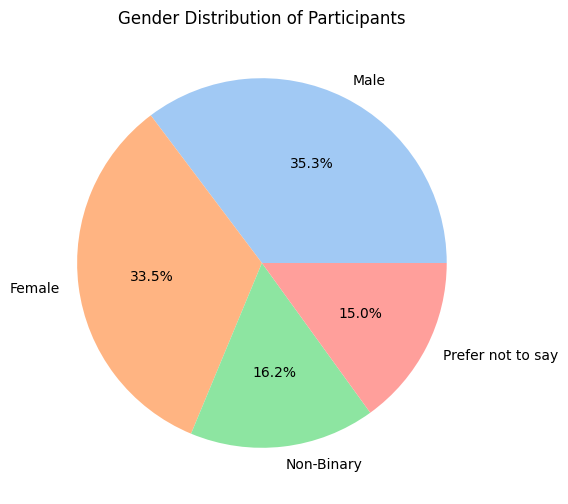

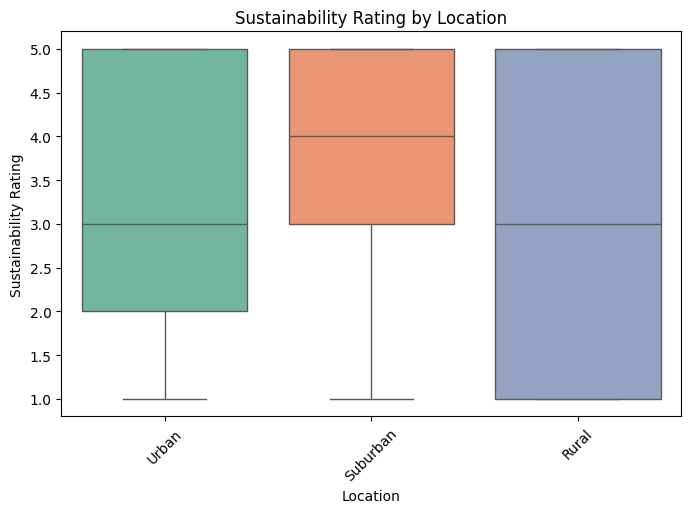

In [7]:
# Gender Distribution
plt.figure(figsize=(6,6))
gender_counts = df['Gender'].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%',
        colors=sns.color_palette("pastel"))
plt.title("Gender Distribution of Participants")
plt.show()

# Location vs Sustainability Rating
plt.figure(figsize=(8,5))
sns.boxplot(x='Location', y='Rating', hue='Location', data=df, palette="Set2", legend=False)
plt.title("Sustainability Rating by Location")
plt.xlabel("Location")
plt.ylabel("Sustainability Rating")
plt.xticks(rotation=45)
plt.show()

## **Preprocessing & Feature Engineering**

In [8]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Handle missing values in key categorical columns
df['CommunityInvolvement'] = df['CommunityInvolvement'].fillna("Unknown")
df['PhysicalActivities'] = df['PhysicalActivities'].fillna("Unknown")

# Drop irrelevant columns
if 'ParticipantID' in df.columns:
    df = df.drop(columns=['ParticipantID'])

# Encode ALL categorical variables
categorical_cols = [
    'Location','DietType','LocalFoodFrequency','TransportationMode',
    'EnergySource','HomeType','ClothingFrequency','SustainableBrands',
    'EnvironmentalAwareness','CommunityInvolvement','Gender',
    'UsingPlasticProducts','DisposalMethods','PhysicalActivities'
]

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Fill All remaining missing values
df_encoded = df_encoded.fillna(0)

# Scale numerical features
num_cols = ['Age','MonthlyElectricityConsumption','MonthlyWaterConsumption','HomeSize']
scaler = StandardScaler()
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

# Define Features (X) and Target (y)
X = df_encoded.drop('Rating', axis=1)
y = df_encoded['Rating']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)


Shape of X: (499, 41)
Shape of y: (499,)


## **Model Building & Evaluation**

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# -------------------------------
# Classification Model
# -------------------------------
# Convert Rating into categories for classification
y_class = pd.cut(y, bins=[0,2,3,5], labels=['Low','Medium','High'])

X_train, X_test, y_train_class, y_test_class = train_test_split(X, y_class, test_size=0.2, random_state=42)

print("\n--- Classification Models ---")

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train_class)
y_pred_log = log_reg.predict(X_test)

print("\nLogistic Regression:")
print("Accuracy:", accuracy_score(y_test_class, y_pred_log))
print("Precision:", precision_score(y_test_class, y_pred_log, average='weighted'))
print("Recall:", recall_score(y_test_class, y_pred_log, average='weighted'))
print("F1-score:", f1_score(y_test_class, y_pred_log, average='weighted'))

# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train_class)
y_pred_dt = dt.predict(X_test)

print("\nDecision Tree:")
print("Accuracy:", accuracy_score(y_test_class, y_pred_dt))
print("Precision:", precision_score(y_test_class, y_pred_dt, average='weighted'))
print("Recall:", recall_score(y_test_class, y_pred_dt, average='weighted'))
print("F1-score:", f1_score(y_test_class, y_pred_dt, average='weighted'))

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train_class)
y_pred_rf = rf.predict(X_test)

print("\nRandom Forest:")
print("Accuracy:", accuracy_score(y_test_class, y_pred_rf))
print("Precision:", precision_score(y_test_class, y_pred_rf, average='weighted'))
print("Recall:", recall_score(y_test_class, y_pred_rf, average='weighted'))
print("F1-score:", f1_score(y_test_class, y_pred_rf, average='weighted'))

# -------------------------------
# Regression Model
# -------------------------------
X_train, X_test, y_train_reg, y_test_reg = train_test_split(X, y, test_size=0.2, random_state=42)

print("\n--- Regression Model ---")

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train_reg)
y_pred_reg = lin_reg.predict(X_test)

print("\nLinear Regression:")
print("RMSE:", np.sqrt(mean_squared_error(y_test_reg, y_pred_reg)))
print("MAE:", mean_absolute_error(y_test_reg, y_pred_reg))
print("R²:", r2_score(y_test_reg, y_pred_reg))



--- Classification Models ---

Logistic Regression:
Accuracy: 0.81
Precision: 0.8060444177671069
Recall: 0.81
F1-score: 0.8075559487784446

Decision Tree:
Accuracy: 0.75
Precision: 0.776042328042328
Recall: 0.75
F1-score: 0.7572597889315521

Random Forest:
Accuracy: 0.88
Precision: 0.8905357142857143
Recall: 0.88
F1-score: 0.8795662042875158

--- Regression Model ---

Linear Regression:
RMSE: 0.9257856899343476
MAE: 0.6860378423421584
R²: 0.6590639469799054


## **Model Performance Summary**

In [10]:
# Summary table comparing metrics across all models

# Collect metrics into a dictionary
results = {
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "Linear Regression"],
    "Accuracy": [
        accuracy_score(y_test_class, y_pred_log),
        accuracy_score(y_test_class, y_pred_dt),
        accuracy_score(y_test_class, y_pred_rf),
        None  # Not applicable for regression
    ],
    "Precision": [
        precision_score(y_test_class, y_pred_log, average='weighted'),
        precision_score(y_test_class, y_pred_dt, average='weighted'),
        precision_score(y_test_class, y_pred_rf, average='weighted'),
        None
    ],
    "Recall": [
        recall_score(y_test_class, y_pred_log, average='weighted'),
        recall_score(y_test_class, y_pred_dt, average='weighted'),
        recall_score(y_test_class, y_pred_rf, average='weighted'),
        None
    ],
    "F1-score": [
        f1_score(y_test_class, y_pred_log, average='weighted'),
        f1_score(y_test_class, y_pred_dt, average='weighted'),
        f1_score(y_test_class, y_pred_rf, average='weighted'),
        None
    ],
    "RMSE": [None, None, None, np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))],
    "MAE": [None, None, None, mean_absolute_error(y_test_reg, y_pred_reg)],
    "R²": [None, None, None, r2_score(y_test_reg, y_pred_reg)]
}

# Convert to DataFrame
results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision  Recall  F1-score      RMSE  \
0  Logistic Regression      0.81   0.806044    0.81  0.807556       NaN   
1        Decision Tree      0.75   0.776042    0.75  0.757260       NaN   
2        Random Forest      0.88   0.890536    0.88  0.879566       NaN   
3    Linear Regression       NaN        NaN     NaN       NaN  0.925786   

        MAE        R²  
0       NaN       NaN  
1       NaN       NaN  
2       NaN       NaN  
3  0.686038  0.659064  


### **Visual Evaluation of Models**

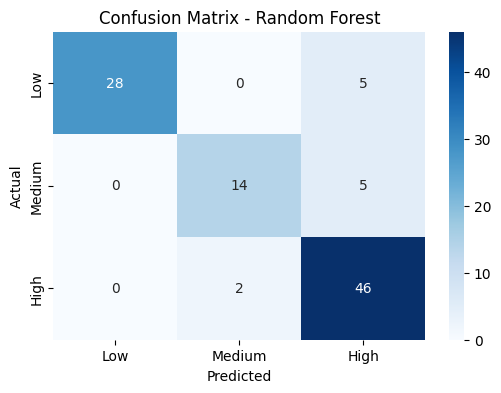

In [11]:
# Confusion Matrix Plot

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Confusion matrix for Random Forest
cm = confusion_matrix(y_test_class, y_pred_rf, labels=['Low','Medium','High'])

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=['Low','Medium','High'], yticklabels=['Low','Medium','High'])
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

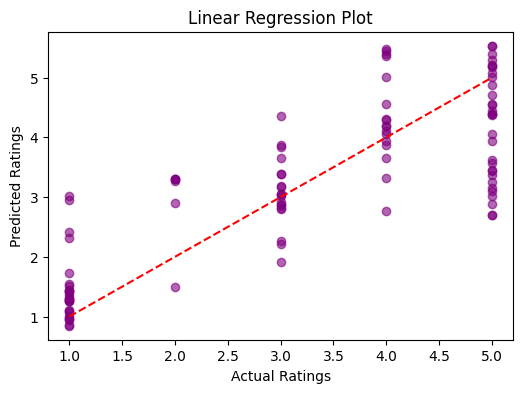

In [12]:
# Regression Plot

plt.figure(figsize=(6,4))
plt.scatter(y_test_reg, y_pred_reg, color="purple", alpha=0.6)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--')  # perfect fit line
plt.title("Linear Regression Plot")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.show()

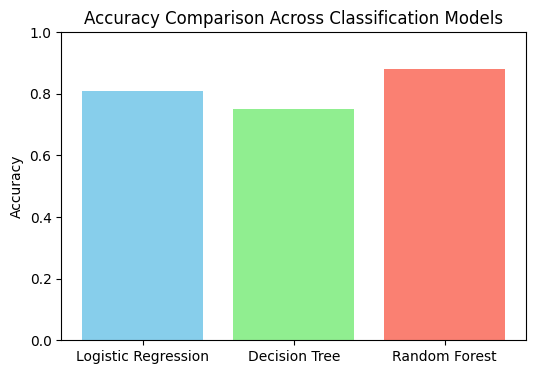

In [13]:
# Accuracy comparison across classification models
import matplotlib.pyplot as plt

accuracies = {
    "Logistic Regression": accuracy_score(y_test_class, y_pred_log),
    "Decision Tree": accuracy_score(y_test_class, y_pred_dt),
    "Random Forest": accuracy_score(y_test_class, y_pred_rf)
}

plt.figure(figsize=(6,4))
plt.bar(accuracies.keys(), accuracies.values(), color=["skyblue","lightgreen","salmon"])
plt.title("Accuracy Comparison Across Classification Models")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.show()

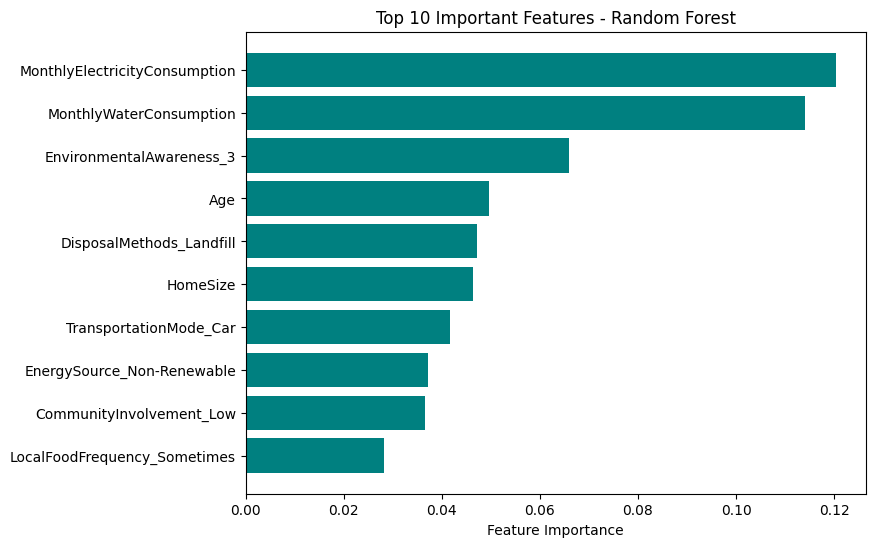

In [14]:
# Feature importance plot from Random Forest
import numpy as np

importances = rf.feature_importances_
indices = np.argsort(importances)[-10:]

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), importances[indices], align="center", color="teal")
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel("Feature Importance")
plt.title("Top 10 Important Features - Random Forest")
plt.show()

## **Hyperparameter Tuning**

In [15]:
# Decision Tree

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_grid_dt = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

# Grid Search
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid_dt,
    cv=5,
    scoring="accuracy"
)

grid_dt.fit(X_train, y_train_class)

best_dt = grid_dt.best_estimator_

print("Best Decision Tree Params:", grid_dt.best_params_)
print("Best CV Accuracy:", grid_dt.best_score_)
print("Tuned DT Test Accuracy:", accuracy_score(y_test_class, best_dt.predict(X_test)))

Best Decision Tree Params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 10}
Best CV Accuracy: 0.7643670886075948
Tuned DT Test Accuracy: 0.7


In [16]:
# Random Forest

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

y_class = pd.cut(
    y, bins=[0, 2, 4, 5], labels=["Low", "Medium", "High"]
)

X_train, X_test, y_train_class, y_test_class = train_test_split(
    X, y_class, test_size=0.2, random_state=42
)

param_grid_rf = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring="accuracy"
)

grid_rf.fit(X_train, y_train_class)

best_rf = grid_rf.best_estimator_

print("Best Random Forest Params:", grid_rf.best_params_)
print("Best CV Accuracy:", grid_rf.best_score_)
print("Tuned RF Test Accuracy:", accuracy_score(y_test_class, best_rf.predict(X_test)))


Best Random Forest Params: {'criterion': 'gini', 'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 0.7519620253164557
Tuned RF Test Accuracy: 0.75


## **Cross-Validation of Tuned Models**

In [17]:
# Cross-Validation for Tuned Models
from sklearn.model_selection import cross_val_score

# Decision Tree Cross-Validation
cv_scores_dt = cross_val_score(best_dt, X, y_class, cv=5, scoring="accuracy")
print("Decision Tree CV Accuracies:", cv_scores_dt)
print("Decision Tree Mean CV Accuracy:", cv_scores_dt.mean())
print("Decision Tree Std Dev:", cv_scores_dt.std())

# Random Forest Cross-Validation
cv_scores_rf = cross_val_score(best_rf, X, y_class, cv=5, scoring="accuracy")
print("\nRandom Forest CV Accuracies:", cv_scores_rf)
print("Random Forest Mean CV Accuracy:", cv_scores_rf.mean())
print("Random Forest Std Dev:", cv_scores_rf.std())

Decision Tree CV Accuracies: [0.88       0.89       0.55       0.48       0.43434343]
Decision Tree Mean CV Accuracy: 0.6468686868686869
Decision Tree Std Dev: 0.1979185330893259

Random Forest CV Accuracies: [0.99       0.98       0.67       0.5        0.50505051]
Random Forest Mean CV Accuracy: 0.7290101010101011
Random Forest Std Dev: 0.217806049400829


## **Baseline vs Tuned Model Comparison**

In [18]:
# Baseline vs Tuned Model Comparison

results_summary = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Baseline Accuracy": [
        accuracy_score(y_test_class, y_pred_dt),
        accuracy_score(y_test_class, y_pred_rf)
    ],
    "Tuned Accuracy": [
        accuracy_score(y_test_class, best_dt.predict(X_test)),
        accuracy_score(y_test_class, best_rf.predict(X_test))
    ],
    "Best CV Accuracy": [
        grid_dt.best_score_,
        grid_rf.best_score_
    ]
})

print(results_summary)

           Model  Baseline Accuracy  Tuned Accuracy  Best CV Accuracy
0  Decision Tree               0.63            0.54          0.764367
1  Random Forest               0.71            0.75          0.751962


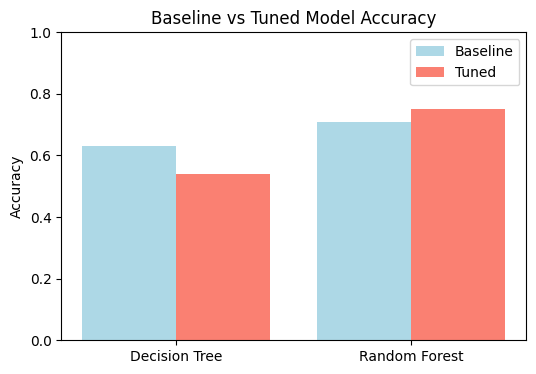

In [19]:
# Baseline vs Tuned Accuracy Visualization
import matplotlib.pyplot as plt

models = ["Decision Tree", "Random Forest"]
baseline_acc = [
    accuracy_score(y_test_class, y_pred_dt),
    accuracy_score(y_test_class, y_pred_rf)
]
tuned_acc = [
    accuracy_score(y_test_class, best_dt.predict(X_test)),
    accuracy_score(y_test_class, best_rf.predict(X_test))
]

x = range(len(models))
plt.figure(figsize=(6,4))
plt.bar(x, baseline_acc, width=0.4, label="Baseline", color="lightblue", align="center")
plt.bar([i+0.4 for i in x], tuned_acc, width=0.4, label="Tuned", color="salmon", align="center")

plt.xticks([i+0.2 for i in x], models)
plt.ylabel("Accuracy")
plt.title("Baseline vs Tuned Model Accuracy")
plt.ylim(0,1)
plt.legend()
plt.show()

## **Conclusion**

This project walked through the full machine learning workflow, from loading and exploring the dataset, to preprocessing and feature engineering, model building, hyperparameter tuning, and cross-validation. We compared multiple models and found that Random Forest consistently delivered the best accuracy and stability. From this, we understood that sustainability ratings are strongly influenced by resource consumption patterns and awareness factors, and that machine learning can effectively capture these relationships. Overall, the project demonstrates how data-driven approaches can provide meaningful insights into sustainable living.

